### Clusterização DBSCAN - Spotify (Audio Features)

**Objetivo**:
Identificar padrões sonoros que atravessem gêneros musicais, a partir de 8 audio features de músicas do Spotify (danceability, energy, loudness, speechiness, acousticness, instrumentalness, valence e tempo).

**Abordagens**
- **Baseline:** DBSCAN nas 8 features escaladas, sem redução de dimensionalidade.
- **PCA:** DBSCAN nos primeiros 3, 4 e 5 componentes principais, número sugerido no notebook do Victor a partir da variância explicada.

**Critérios de sucesso do MVP**
- **Similaridade sonora:** os clusters são coerentes? (silhouette sem ruído, % de ruído e tamanho dos clusters)
- **Diversidade de gêneros:** os clusters misturam gêneros em vez de reproduzi-los? (gênero dominante e entropia de gêneros)

Como o DBSCAN é mais pesado, a busca de parâmetros usa uma amostra de 10 mil músicas (a mesma amostra para todos os modelos).

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Adiciona a pasta raiz do projeto ao caminho de busca (a pasta app fica fora da pasta notebooks)
sys.path.append("..")

from app.preprocessing.preprocessing import preprocessing
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

### Spotify Tracks Dataset

In [3]:
# Carrega dados de músicas do Spotify
df = pd.read_csv("../raw_data/spotify-tracks-dataset-detailed.csv")
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [4]:
# Verifica quantidade de linhas da base
len(df)

114000

### 1. Pre Processing

- A função `preprocessing` reúne todas as etapas de preparação da base em um único lugar, para que o mesmo tratamento possa ser reaplicado de forma idêntica. As etapas, nesta ordem, são: remoção do gênero comedy, seleção das colunas necessárias, remoção de valores nulos, remoção de duplicatas exatas, preservação de todos os gêneros de cada música (uma música pode aparecer em mais de um gênero), manutenção de uma linha por música, separação entre metadados e features e escalonamento das features.

- Para o escalonamento foi adotado o StandardScaler, que padroniza os valores para média 0 e desvio padrão 1. Como o DBSCAN é baseado em distância, features em escalas muito diferentes (como loudness e tempo, em relação às variáveis entre 0 e 1) dominariam o cálculo se não fossem padronizadas. O scaler foi ajustado na base completa, uma vez que não há divisão entre treino e teste na clusterização.

#### 1.1 Aplicação do Pre Processing

In [5]:
# Aplica o pre processing na base
X_scaled, df_metadata, scaler, features = preprocessing(df)

In [6]:
# Verifica o formato da matriz de features escaladas
X_scaled.shape

(88751, 8)

In [7]:
# Verifica os metadados das músicas
df_metadata.head()

,track_id,artists,track_name,genres
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,"[acoustic, j-pop, singer-songwriter, songwriter]"
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,"[acoustic, chill]"
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,[acoustic]
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,[acoustic]
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,[acoustic]


In [8]:
# Cria o dataframe com as features escaladas
df_scaled = pd.DataFrame(X_scaled, columns=features)
df_scaled.head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,0.642976,-0.671544,0.331501,0.761537,-0.866112,-0.539305,0.931651,-1.143959
1,-0.800829,-1.818558,-1.676941,-0.043998,1.782308,-0.539291,-0.769508,-1.490966
2,-0.699312,-1.068138,-0.240643,-0.292784,-0.338091,-0.539308,-1.327701,-1.529466
3,-1.669368,-2.232261,-1.922037,-0.527078,1.725883,-0.539091,-1.240365,1.978131
4,0.315863,-0.741531,-0.230495,-0.330223,0.431074,-0.539308,-1.149232,-0.078050


In [9]:
# Une os metadados com as features escaladas
df_final = pd.concat([df_metadata, df_scaled], axis=1)
df_final.head()

,track_id,artists,track_name,genres,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,"[acoustic, j-pop, singer-songwriter, songwriter]",0.642976,-0.671544,0.331501,0.761537,-0.866112,-0.539305,0.931651,-1.143959
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,"[acoustic, chill]",-0.800829,-1.818558,-1.676941,-0.043998,1.782308,-0.539291,-0.769508,-1.490966
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,[acoustic],-0.699312,-1.068138,-0.240643,-0.292784,-0.338091,-0.539308,-1.327701,-1.529466
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,[acoustic],-1.669368,-2.232261,-1.922037,-0.527078,1.725883,-0.539091,-1.240365,1.978131
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,[acoustic],0.315863,-0.741531,-0.230495,-0.330223,0.431074,-0.539308,-1.149232,-0.078050


- Energy, loudness e acousticness são fortemente correlacionadas e pesam como um único eixo de "intensidade" na distância dos algoritmos.
- Speechiness, instrumentalness e acousticness têm distribuição muito assimétrica, e loudness e duration têm outliers. Isso afeta o `StandardScaler`.

### 2. Espaços do Modelo - Baseline e PCA

#### 2.1 Baseline (8 features)

O baseline roda o DBSCAN nas 8 features já escaladas (`X_scaled`), sem redução de dimensionalidade.

In [10]:
# Define os espaços em que cada modelo vai rodar, começando pelo baseline (8 features escaladas)
espacos = {"Baseline (8 features)": X_scaled}

#### 2.2 PCA - Variância Explicada

Seguindo o gráfico de variância explicada do PCA, optei por testar **3, 4 e 5 componentes**.

Com 8 componentes o PCA é só uma rotação dos dados, que preserva as distâncias. Rodar o modelo nos 8 PCs daria o mesmo resultado do baseline, então só faz sentido usar menos componentes.

In [11]:
# Ajusta o PCA com todos os componentes (mesmo PCA do Victor, 8 componentes)
pca_full = PCA().fit(X_scaled)

# Calcula a variância explicada e acumulada por componente
variancia = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, len(features) + 1)],
    "variancia_explicada": pca_full.explained_variance_ratio_,
    "variancia_acumulada": np.cumsum(pca_full.explained_variance_ratio_),
})
variancia.round(4)

,PC,variancia_explicada,variancia_acumulada
0,PC1,0.3656,0.3656
1,PC2,0.1753,0.5410
2,PC3,0.1218,0.6627
3,PC4,0.1126,0.7753
4,PC5,0.1049,0.8802
5,PC6,0.0612,0.9414
6,PC7,0.0407,0.9821
7,PC8,0.0179,1.0000


#### 2.3 PCA - Loadings

In [12]:
# Calcula o peso de cada feature nos 5 primeiros componentes
loadings = pd.DataFrame(
    pca_full.components_.T,
    index=features,
    columns=[f"PC{i}" for i in range(1, len(features) + 1)]
)

loadings.iloc[:, :5].round(2)

,PC1,PC2,PC3,PC4,PC5
danceability,0.26,0.53,0.14,-0.25,0.40
energy,0.50,-0.30,-0.05,-0.17,0.02
loudness,0.51,-0.09,-0.16,-0.03,-0.20
speechiness,0.15,0.05,0.94,-0.01,-0.28
acousticness,-0.44,0.35,0.03,0.31,-0.09
instrumentalness,-0.28,-0.35,0.22,-0.38,0.67
valence,0.30,0.54,-0.08,0.12,0.31
tempo,0.20,-0.28,0.14,0.81,0.42


#### 2.4 PCA - Espaços com 3, 4 e 5 Componentes

In [13]:
# Define a quantidade de componentes testados
N_COMPONENTES = [3, 4, 5]

# Cria os espaços reduzidos do PCA e adiciona aos espaços do modelo
for n in N_COMPONENTES:
    espacos[f"PCA {n}"] = PCA(n_components=n).fit_transform(X_scaled)

In [14]:
# Verifica o formato de cada espaço (baseline e PCA com 3, 4 e 5 componentes)
for nome, M in espacos.items():
    print(nome, M.shape)

Baseline (8 features) (88751, 8)
PCA 3 (88751, 3)
PCA 4 (88751, 4)
PCA 5 (88751, 5)


### 3. Amostra e Funções Auxiliares de Avaliação

- **Mesma amostra para todos os modelos.** A amostra de 10 mil músicas é sorteada uma única vez, então baseline e PCA são comparados nas mesmas músicas.
- **Métricas do DBSCAN:** além do silhouette (calculado só nos pontos que não são ruído), acompanhamos `ruido_pct` e `maior_cluster_pct`. O silhouette sozinho engana no DBSCAN: um resultado com 1 cluster gigante mais um minúsculo e quase nenhum ruído pode ter silhouette alto e ser inútil para o recomendador.
- **silhouette_8d:** o silhouette dos mesmos clusters medido no espaço das 8 features originais, para comparar baseline e PCA no mesmo referencial (o silhouette de cada modelo é medido no espaço em que ele foi treinado, com 8, 3, 4 ou 5 dimensões).
- **genero_dominante_pct** (menor = mais misturado) e **entropia_generos** (maior = mais diverso): ligadas ao critério de diversidade de gêneros do MVP.

#### 3.1 Amostra

In [15]:
# Define o tamanho da amostra usada na busca de parâmetros
N_AMOSTRA = 10000

# Sorteia a amostra uma única vez (mesma amostra para todos os modelos)
idx_amostra = df_scaled.sample(n=N_AMOSTRA, random_state=42).index
pos_amostra = idx_amostra.to_numpy()

# Seleciona as músicas da amostra em cada espaço
espacos_amostra = {nome: M[pos_amostra] for nome, M in espacos.items()}

# Define o espaço de referência (8 features) usado no silhouette_8d
X_amostra_base = espacos_amostra["Baseline (8 features)"]

# Verifica o formato de cada espaço na amostra
print({nome: M.shape for nome, M in espacos_amostra.items()})

{'Baseline (8 features)': (10000, 8), 'PCA 3': (10000, 3), 'PCA 4': (10000, 4), 'PCA 5': (10000, 5)}


#### 3.2 Métricas de Gêneros

In [16]:
# Cria uma linha por par música-gênero
genres_exp = df_metadata["genres"].explode().rename("genre")

# Conta a quantidade de gêneros distintos (usada para normalizar a entropia)
N_GENEROS = genres_exp.nunique()

In [17]:
def metricas_genero(labels):
    """Mede o quanto os clusters misturam gêneros (ligado ao critério de diversidade de gêneros do MVP).

    labels: pd.Series com o cluster de cada música (índice = índice de df_metadata). Ruído deve ser removido antes.
    - genero_dominante_pct: share do gênero mais comum em cada cluster, ponderado pelo tamanho do cluster (menor = mais misturado)
    - entropia_generos: entropia normalizada (0 a 1) da distribuição de gêneros em cada cluster, ponderada pelo tamanho (maior = mais diverso)
    """
    # Cruza os gêneros de cada música com o seu cluster
    g = genres_exp.to_frame().join(labels.rename("cluster"), how="inner")

    # Conta a quantidade de músicas por cluster e gênero
    tab = g.groupby(["cluster", "genre"]).size().unstack(fill_value=0)

    # Calcula a distribuição de gêneros dentro de cada cluster e o peso (tamanho) de cada cluster
    p = tab.div(tab.sum(axis=1), axis=0)
    peso = tab.sum(axis=1) / tab.values.sum()

    # Calcula o gênero dominante e a entropia, ponderados pelo tamanho do cluster
    dominante = (p.max(axis=1) * peso).sum() * 100
    entropia = (-(p * np.log(p.where(p > 0, 1))).sum(axis=1) / np.log(N_GENEROS) * peso).sum()
    return {"genero_dominante_pct": dominante, "entropia_generos": entropia}

#### 3.3 Perfil dos Clusters

In [18]:
def perfil_clusters(labels, top_n=3):
    """Média das 8 features (escaladas) por cluster, tamanho do cluster e gêneros mais comuns. Ignora ruído (-1)."""
    # Remove o ruído (-1) e nomeia a série de clusters
    labels = labels[labels != -1].rename("cluster")

    # Calcula a média de cada feature escalada por cluster
    medias = df_scaled.loc[labels.index].groupby(labels).mean()

    # Identifica os gêneros mais comuns de cada cluster
    g = genres_exp.to_frame().join(labels, how="inner")
    top = g.groupby("cluster")["genre"].agg(lambda s: ", ".join(s.value_counts().head(top_n).index))

    # Monta o perfil com o percentual de músicas e os gêneros mais comuns
    perfil = medias.copy()
    perfil["pct_musicas"] = labels.value_counts(normalize=True).sort_index() * 100
    perfil["top_generos"] = top
    return perfil


def plot_perfil(perfil, titulo, ax):
    """Heatmap com a média de cada feature (em desvios-padrão) por cluster."""
    medias = perfil[features]
    im = ax.imshow(medias.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(len(features)))
    ax.set_xticklabels(features, rotation=45, ha="right")
    ax.set_yticks(range(len(medias)))
    ax.set_yticklabels([f"c{c} ({p:.0f}%)" for c, p in zip(medias.index, perfil["pct_musicas"])])
    ax.set_title(titulo)
    return im

### 4. K-Distance Plot (um por espaço)

O `eps` do DBSCAN depende do espaço: ao reduzir de 8 para 3-5 dimensões as distâncias encolhem, então **o `eps` do baseline não pode ser reaproveitado no PCA**. Por isso o K-Distance Plot é refeito para cada espaço e para alguns valores de `min_samples`.

Em vez de um grid fixo de `eps` (0,5; 0,7; ...), optei por escolher o `eps` por **quantis da própria curva de k-distância**. Um ponto é *core* quando o seu k-ésimo vizinho está dentro de `eps`, então `eps` no quantil 0,90 faz cerca de 90% dos pontos serem core. Isso deixa a busca equivalente entre os espaços.

#### 4.1 Cálculo da K-Distância

In [19]:
# Define os valores de min_samples testados
MIN_SAMPLES = [5, 10, 20]

# Define os quantis da curva de k-distância usados para escolher o eps
QUANTIS_EPS = [0.60, 0.70, 0.80, 0.90, 0.95, 0.99]


def k_distancias(Xs, min_samples):
    """Distância de cada ponto ao seu min_samples-ésimo vizinho (o próprio ponto conta, como no DBSCAN), ordenada."""
    # Encontra os vizinhos mais próximos de cada ponto
    nn = NearestNeighbors(n_neighbors=min_samples).fit(Xs)
    dist, _ = nn.kneighbors(Xs)

    # Ordena a distância ao k-ésimo vizinho
    return np.sort(dist[:, -1])

In [20]:
# Calcula a k-distância de cada espaço para cada valor de min_samples
kdists = {
    (nome, ms): k_distancias(Xs, ms)
    for nome, Xs in espacos_amostra.items()
    for ms in MIN_SAMPLES
}

#### 4.2 K-Distance Plot

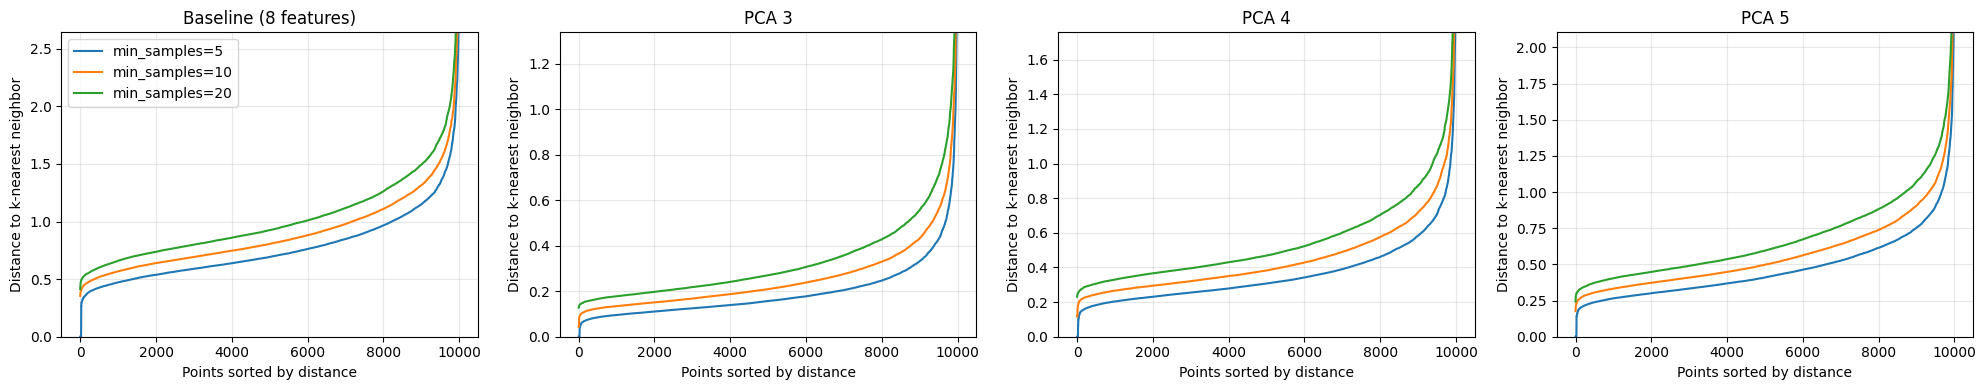

In [21]:
# K-Distance Plot: mostra a distância ao k-ésimo vizinho de cada ponto e ajuda a escolher o eps.
fig, axes = plt.subplots(1, len(espacos_amostra), figsize=(5 * len(espacos_amostra), 4))

for ax, nome in zip(axes, espacos_amostra):
    for ms in MIN_SAMPLES:
        ax.plot(kdists[(nome, ms)], label=f"min_samples={ms}")
    ax.set_ylim(0, np.quantile(np.concatenate([kdists[(nome, ms)] for ms in MIN_SAMPLES]), 0.995))
    ax.set_title(nome)
    ax.set_xlabel("Points sorted by distance")
    ax.set_ylabel("Distance to k-nearest neighbor")
    ax.grid(alpha=0.3)

axes[0].legend()
plt.tight_layout()
plt.show()

### 5. Busca de Parâmetros (eps x min_samples) em cada Espaço

Para cada combinação, treinei o DBSCAN na amostra e registrei número de clusters, ruído, tamanho do maior cluster e silhouette (sem ruído). Esta é a versão ampliada da tabela de silhouette por `eps` que existia antes.

#### 5.1 Busca de Parâmetros

In [22]:
def varrer_dbscan(nome):
    """Treina o DBSCAN para cada combinação de min_samples e quantil de eps em um espaço e retorna as métricas de cada uma."""
    # Seleciona as músicas da amostra no espaço do modelo
    Xs = espacos_amostra[nome]
    linhas = []
    for ms in MIN_SAMPLES:
        for q in QUANTIS_EPS:
            # Define o eps pelo quantil da curva de k-distância e treina o DBSCAN
            eps = float(np.quantile(kdists[(nome, ms)], q))
            labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xs)

            # Separa os pontos que não são ruído e conta os clusters
            ok = labels != -1
            n_clusters = len(set(labels[ok]))

            # Calcula as métricas de clusters, ruído e tamanho do maior cluster
            linha = {
                "espaco": nome,
                "min_samples": ms,
                "quantil_eps": q,
                "eps": eps,
                "clusters": n_clusters,
                "ruido_pct": (~ok).mean() * 100,
                "maior_cluster_pct": np.bincount(labels[ok]).max() / len(labels) * 100 if n_clusters > 0 else 0.0,
                "silhouette": np.nan,
                "silhouette_8d": np.nan,
            }

            # Calcula o silhouette (sem ruído) só quando há 2 ou mais clusters
            if n_clusters >= 2:
                linha["silhouette"] = silhouette_score(Xs[ok], labels[ok])
                linha["silhouette_8d"] = silhouette_score(X_amostra_base[ok], labels[ok])
            linhas.append(linha)
        print(f"{nome} | min_samples={ms} ok")
    return pd.DataFrame(linhas)

In [23]:
# Varre eps x min_samples em cada espaço (baseline e PCA)
res_dbscan = pd.concat([varrer_dbscan(nome) for nome in espacos_amostra], ignore_index=True)

Baseline (8 features) | min_samples=5 ok
Baseline (8 features) | min_samples=10 ok
Baseline (8 features) | min_samples=20 ok
PCA 3 | min_samples=5 ok
PCA 3 | min_samples=10 ok
PCA 3 | min_samples=20 ok
PCA 4 | min_samples=5 ok
PCA 4 | min_samples=10 ok
PCA 4 | min_samples=20 ok
PCA 5 | min_samples=5 ok
PCA 5 | min_samples=10 ok
PCA 5 | min_samples=20 ok


#### 5.2 Resultados - Baseline

In [24]:
# Verifica os resultados da busca de parâmetros no baseline
res_dbscan[res_dbscan["espaco"] == "Baseline (8 features)"].drop(columns="espaco").round(3)

,min_samples,quantil_eps,eps,clusters,ruido_pct,maior_cluster_pct,silhouette,silhouette_8d
0,5,0.60,0.761,23,28.63,66.85,-0.108,-0.108
1,5,0.70,0.848,18,20.32,75.30,-0.139,-0.139
2,5,0.80,0.966,15,12.15,87.14,-0.133,-0.133
3,5,0.90,1.149,4,5.07,94.74,0.147,0.147
4,5,0.95,1.330,3,2.69,97.17,0.307,0.307
5,5,0.99,1.917,1,0.62,99.38,NaN,NaN
6,10,0.60,0.881,4,24.21,72.30,0.261,0.261
7,10,0.70,0.978,3,16.70,79.22,0.280,0.280
8,10,0.80,1.109,1,9.35,90.65,NaN,NaN
9,10,0.90,1.315,1,3.94,96.06,NaN,NaN


#### 5.3 Resultados - PCA

In [25]:
# Verifica os resultados da busca de parâmetros nos espaços do PCA
res_dbscan[res_dbscan["espaco"] != "Baseline (8 features)"].round(3)

,espaco,min_samples,quantil_eps,eps,clusters,ruido_pct,maior_cluster_pct,silhouette,silhouette_8d
18,PCA 3,5,0.60,0.178,101,29.57,62.87,-0.425,-0.339
19,PCA 3,5,0.70,0.205,84,20.92,72.47,-0.371,-0.289
20,PCA 3,5,0.80,0.247,38,13.97,81.14,-0.297,-0.229
21,PCA 3,5,0.90,0.332,16,6.48,92.43,-0.164,-0.102
22,PCA 3,5,0.95,0.430,6,2.96,96.77,0.111,0.085
23,PCA 3,5,0.99,0.787,1,0.64,99.36,NaN,NaN
24,PCA 3,10,0.60,0.238,15,28.64,69.80,-0.302,-0.091
25,PCA 3,10,0.70,0.276,17,20.67,76.60,-0.161,-0.083
26,PCA 3,10,0.80,0.330,5,11.96,87.49,0.210,0.145
27,PCA 3,10,0.90,0.433,3,5.70,94.15,-0.036,-0.005


Resultados da rodada na amostra de 10 mil músicas (`random_state=42`), com 18 configurações por espaço (72 no total).

Silhouettes positivos só aparecem com 1 a 4 clusters e um cluster que concentra de 75% a 97% das músicas (por exemplo, baseline com `min_samples=20` e quantil 0,70: 2 clusters, silhouette 0,425, mas com 82% das músicas num só). É o caso em que o silhouette engana, porque o resultado é inútil para o recomendador.

### 6. Model Selection

#### 6.1 Escolha da Configuração de cada Modelo

Para usar o DBSCAN no recomendador, os clusters precisam ser poucos, interpretáveis e cobrir a maior parte das músicas. Uma configuração só **atende os filtros** se tiver:

- no máximo `MAX_RUIDO_PCT` de ruído;
- pelo menos `MIN_CLUSTERS` clusters;
- nenhum cluster com mais de `MAX_DOMINANTE_PCT` das músicas;
- silhouette acima de `MIN_SILHOUETTE`.

Entre as que atendem, vale a de maior silhouette. Se nenhuma atender, o notebook avisa e usa como **melhor tentativa** a configuração com 3 ou mais clusters e ruído aceitável que tenha o menor cluster dominante. A coluna `atende_filtros` da tabela final mostra qual foi o caso, para a comparação não esconder que um modelo falhou.

In [26]:
# Define os filtros que uma configuração precisa atender
MAX_RUIDO_PCT = 30
MIN_CLUSTERS = 3
MAX_DOMINANTE_PCT = 50
MIN_SILHOUETTE = 0.0


def escolher_config(res_esp):
    """Devolve (configuração, atende_filtros)."""
    nome = res_esp["espaco"].iloc[0]

    # Identifica as configurações com ruído aceitável e clusters suficientes
    base = (res_esp["ruido_pct"] <= MAX_RUIDO_PCT) & (res_esp["clusters"] >= MIN_CLUSTERS)

    # Identifica as configurações que atendem todos os filtros
    valido = base & (res_esp["maior_cluster_pct"] <= MAX_DOMINANTE_PCT) & (res_esp["silhouette"] > MIN_SILHOUETTE)

    # Escolhe a de maior silhouette entre as que atendem os filtros
    if valido.any():
        return res_esp[valido].sort_values("silhouette", ascending=False).iloc[0], True

    # Se nenhuma atender, usa a melhor tentativa (menor cluster dominante)
    print(f"  {nome}: nenhuma configuração atende os filtros; usando a melhor tentativa (menor cluster dominante).")
    if base.any():
        return res_esp[base].sort_values("maior_cluster_pct").iloc[0], False
    return None, False

#### 6.2 Performance Metrics

In [27]:
# Cria os dicionários e a lista que guardam a configuração, os clusters e as métricas de cada modelo
configs, labels_dbscan, linhas = {}, {}, []

# Escolhe a configuração, treina o DBSCAN final e calcula as métricas de cada espaço
for nome in espacos_amostra:
    cfg, atende = escolher_config(res_dbscan[res_dbscan["espaco"] == nome])
    if cfg is None:
        print(f"{nome}: nenhuma configuração formou {MIN_CLUSTERS} ou mais clusters com ruído aceitável.")
        continue

    # Treina o DBSCAN com a configuração escolhida e guarda o cluster de cada música da amostra
    configs[nome] = cfg
    model = DBSCAN(eps=cfg["eps"], min_samples=int(cfg["min_samples"]))
    serie = pd.Series(model.fit_predict(espacos_amostra[nome]), index=idx_amostra)
    labels_dbscan[nome] = serie

    # Reúne as métricas do modelo em uma linha (métricas de gênero sem o ruído)
    linhas.append({
        "espaco": nome,
        "atende_filtros": atende,
        "eps": cfg["eps"],
        "min_samples": int(cfg["min_samples"]),
        "clusters": cfg["clusters"],
        "ruido_pct": cfg["ruido_pct"],
        "maior_cluster_pct": cfg["maior_cluster_pct"],
        "silhouette": cfg["silhouette"],
        "silhouette_8d": cfg["silhouette_8d"],
        **metricas_genero(serie[serie != -1]),
    })

  Baseline (8 features): nenhuma configuração atende os filtros; usando a melhor tentativa (menor cluster dominante).
  PCA 3: nenhuma configuração atende os filtros; usando a melhor tentativa (menor cluster dominante).
  PCA 4: nenhuma configuração atende os filtros; usando a melhor tentativa (menor cluster dominante).
  PCA 5: nenhuma configuração atende os filtros; usando a melhor tentativa (menor cluster dominante).


In [28]:
# Compara o resultado das métricas de performance para todos os modelos
comparacao_dbscan = pd.DataFrame(linhas)
comparacao_dbscan.round(3)

,espaco,atende_filtros,eps,min_samples,clusters,ruido_pct,maior_cluster_pct,silhouette,silhouette_8d,genero_dominante_pct,entropia_generos
0,Baseline (8 features),False,0.761,5,23,28.63,66.85,-0.108,-0.108,2.656,0.959
1,PCA 3,False,0.178,5,101,29.57,62.87,-0.425,-0.339,3.732,0.928
2,PCA 4,False,0.342,5,69,28.91,66.19,-0.402,-0.325,3.225,0.948
3,PCA 5,False,0.464,5,49,29.82,61.53,-0.248,-0.225,3.680,0.928


- **Nenhuma configuração atende os filtros em nenhum espaço**, nem no baseline nem no PCA. Sempre que o DBSCAN forma 3 ou mais clusters com ruído aceitável, o maior cluster tem pelo menos 61% de todas as músicas, e quase toda a massa fica num cluster só.
- As melhores tentativas (menor cluster dominante) têm silhouette **negativo**: baseline -0,108, PCA 3 -0,425, PCA 4 -0,402 e PCA 5 -0,248. No baseline são 23 clusters, com 93,7% das músicas não-ruído num deles, e os outros 22 têm 4% ou menos.
- **O PCA não ajudou o DBSCAN.** Com 3 a 5 componentes, as melhores tentativas viram dezenas ou centenas de clusters minúsculos (49 a 101) mais um cluster gigante, e o silhouette piora em relação ao baseline.

#### 6.3 Perfil dos Clusters

A média das 8 features (em desvios-padrão) de cada cluster, sempre nas features originais, para dar para comparar baseline e PCA. Entre parênteses está o percentual de músicas da amostra no cluster; o ruído fica de fora.

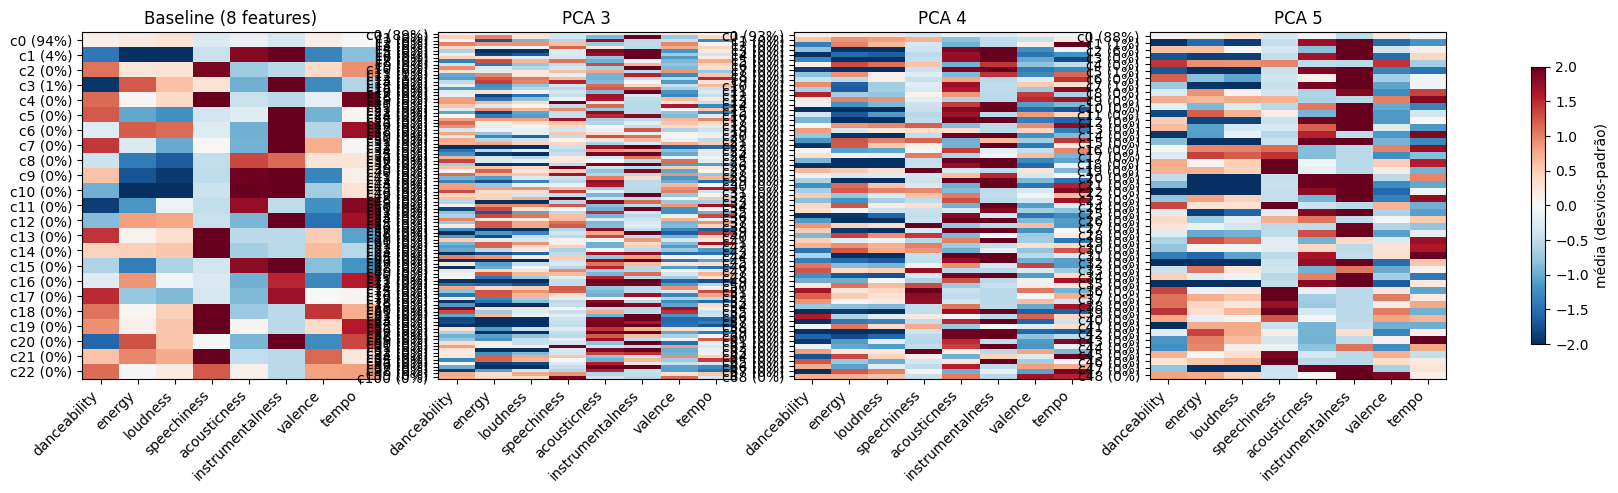

In [29]:
# Plota o perfil dos clusters de cada modelo: média de cada feature (em desvios-padrão) por cluster
fig, axes = plt.subplots(1, len(labels_dbscan), figsize=(5.5 * len(labels_dbscan), 4.5), squeeze=False)
perfis = {}

for ax, (nome, serie) in zip(axes[0], labels_dbscan.items()):
    perfis[nome] = perfil_clusters(serie)
    im = plot_perfil(perfis[nome], nome, ax)

fig.colorbar(im, ax=axes, shrink=0.8, label="média (desvios-padrão)")
plt.show()

In [30]:
# Exibe o percentual de músicas e os gêneros mais comuns de cada cluster
for nome, perfil in perfis.items():
    print(f"\n{nome}")
    display(perfil[["pct_musicas", "top_generos"]].round(1))


Baseline (8 features)


,pct_musicas,top_generos
cluster,,
0,93.7,"heavy-metal, gospel, grunge"
1,4.0,"new-age, ambient, piano"
2,0.2,"sad, dub, french"
3,0.7,"grindcore, black-metal, death-metal"
4,0.1,"reggaeton, reggae, latino"
5,0.0,"detroit-techno, deep-house"
6,0.1,drum-and-bass
7,0.1,chicago-house
8,0.1,"jazz, afrobeat, tango"



PCA 3


,pct_musicas,top_generos
cluster,,
0,89.3,"heavy-metal, gospel, pagode"
1,0.1,"minimal-techno, trance, breakbeat"
2,0.1,"honky-tonk, disney, acoustic"
3,0.4,"house, party, reggaeton"
4,0.1,"psych-rock, french, j-rock"
...,...,...
96,0.1,"disney, british, folk"
97,0.1,"ambient, piano, classical"
98,0.1,"ambient, cantopop, opera"



PCA 4


,pct_musicas,top_generos
cluster,,
0,93.1,"heavy-metal, gospel, j-idol"
1,0.1,"house, edm, progressive-house"
2,0.1,"brazil, mpb, r-n-b"
3,0.2,"new-age, disney, british"
4,0.3,"iranian, new-age, classical"
...,...,...
64,0.0,"grindcore, hardcore, ska"
65,0.1,"minimal-techno, idm, detroit-techno"
66,0.0,"acoustic, honky-tonk, singer-songwriter"



PCA 5


,pct_musicas,top_generos
cluster,,
0,87.7,"gospel, heavy-metal, grunge"
1,0.5,"new-age, iranian, opera"
2,5.7,"minimal-techno, detroit-techno, techno"
3,0.1,"new-age, idm, ambient"
4,0.1,"j-dance, hip-hop, kids"
5,1.1,"sleep, ambient, new-age"
6,0.1,"minimal-techno, deep-house, detroit-techno"
7,0.6,"new-age, piano, ambient"
8,0.1,"happy, drum-and-bass, electronic"


#### 6.4 Visualização dos Clusters (PC1 x PC2)

Todos os modelos desenhados na mesma projeção PC1 x PC2, com o ruído em cinza.

In [31]:
# Projeta as músicas em PC1 x PC2 (mesma projeção para todos os modelos)
pcs_2d = pca_full.transform(X_scaled)[:, :2]


def plot_pc12(idx, labels, titulo, ax):
    """Dispersão em PC1 x PC2. idx = posições das músicas plotadas; labels = cluster de cada uma (ruído = -1 em cinza)."""
    labels = np.asarray(labels)
    ruido = labels == -1
    ax.scatter(pcs_2d[idx[ruido], 0], pcs_2d[idx[ruido], 1], c="lightgrey", s=3, alpha=0.4)
    ax.scatter(pcs_2d[idx[~ruido], 0], pcs_2d[idx[~ruido], 1], c=labels[~ruido], cmap="tab10", s=4, alpha=0.6)
    ax.set_title(titulo)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

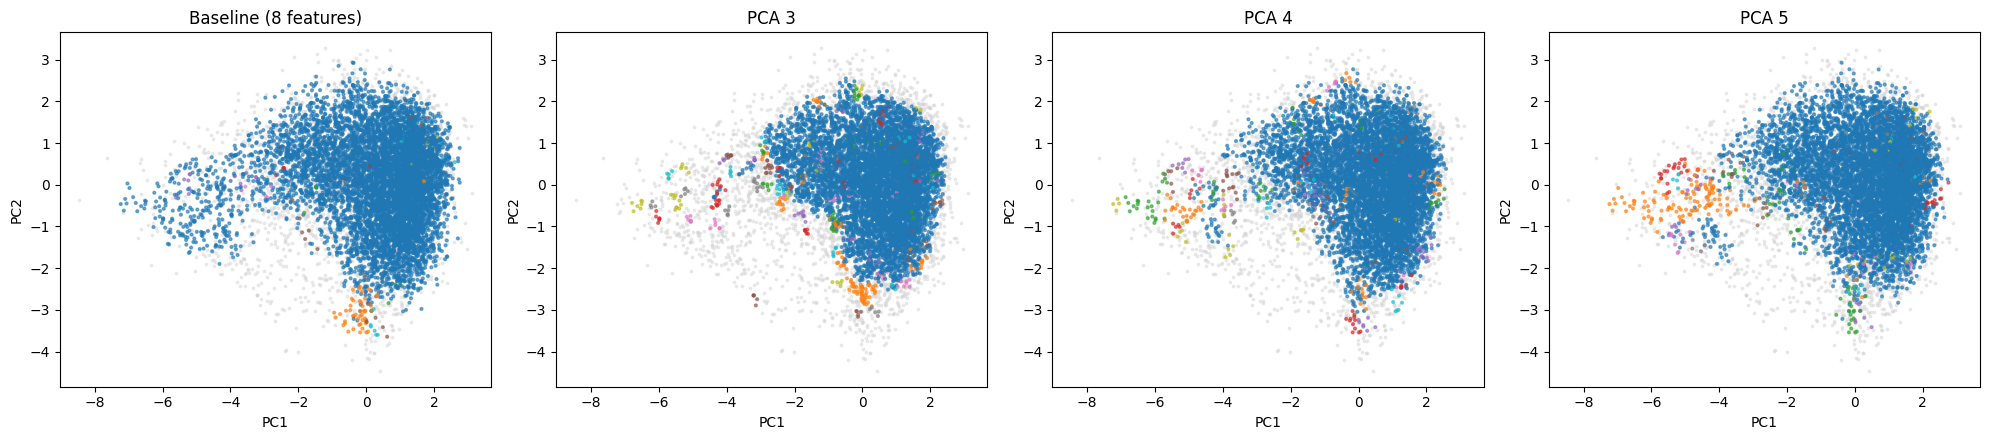

In [32]:
# Plota os clusters de cada modelo na projeção PC1 x PC2 (ruído em cinza)
fig, axes = plt.subplots(1, len(labels_dbscan), figsize=(5 * len(labels_dbscan), 4.5), squeeze=False)

for ax, (nome, serie) in zip(axes[0], labels_dbscan.items()):
    plot_pc12(serie.index.to_numpy(), serie.to_numpy(), nome, ax)

plt.tight_layout()
plt.show()

### 7. Conclusão

- Audio features do Spotify formam mais um contínuo do que grupos separados por regiões vazias, e o DBSCAN depende justamente de regiões de densidade separadas. Isso é uma limitação do DBSCAN neste dado, e não um erro de código.
- Os parâmetros foram escolhidos numa amostra de 10 mil músicas. Numa base maior, a mesma `eps` com o mesmo `min_samples` encontra mais vizinhos por ponto e os clusters tendem a se juntar ainda mais, então o cenário completo não deve ser melhor.
- **Conclusão:** o DBSCAN, com ou sem PCA, não produz taste clusters utilizáveis neste dado. Isso é um resultado útil: justifica a escolha do K-Means para o recomendador.